# Data Loading

In [10]:
import pandas as pd

data = pd.read_csv("predictions.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
2091,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.315926
1828,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,4.811844
948,0,Escherichia coli,COC(=O)c1cccc(-c2ccc(O[C@H]3O[C@H](CO)[C@@H](O...,6.050610,6.295602
3160,0,Pseudoalteromonas ulvae,COc1ccc(CCNC(=O)c2cn(-c3cccc(OC)c3)nn2)cc1,4.943095,4.305500
1763,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.078073


# Prediction Analysis

## Metrics

In [11]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.466325,0.341658,0.225841,0.475227
Split 1,0.441642,0.401080,0.308398,0.555336
Split 2,0.516565,0.344538,0.213652,0.462225
Split 3,0.428647,0.398597,0.323267,0.568566
Split 4,0.436165,0.368197,0.270322,0.519925
Split 5,0.527139,0.370506,0.250137,0.500137
Split 6,0.482055,0.336905,0.218686,0.467639
Split 7,0.326849,0.388185,0.290835,0.539291
Split 8,0.471934,0.368793,0.273812,0.523271
Split 9,0.552094,0.336836,0.212348,0.460813


# Graph

Text(0, 0.5, 'predicted pIC50')

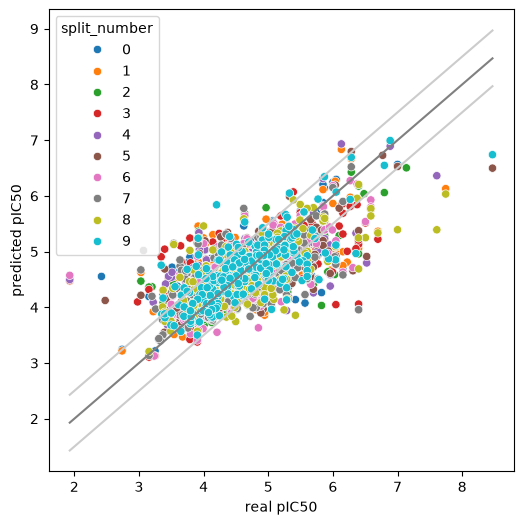

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

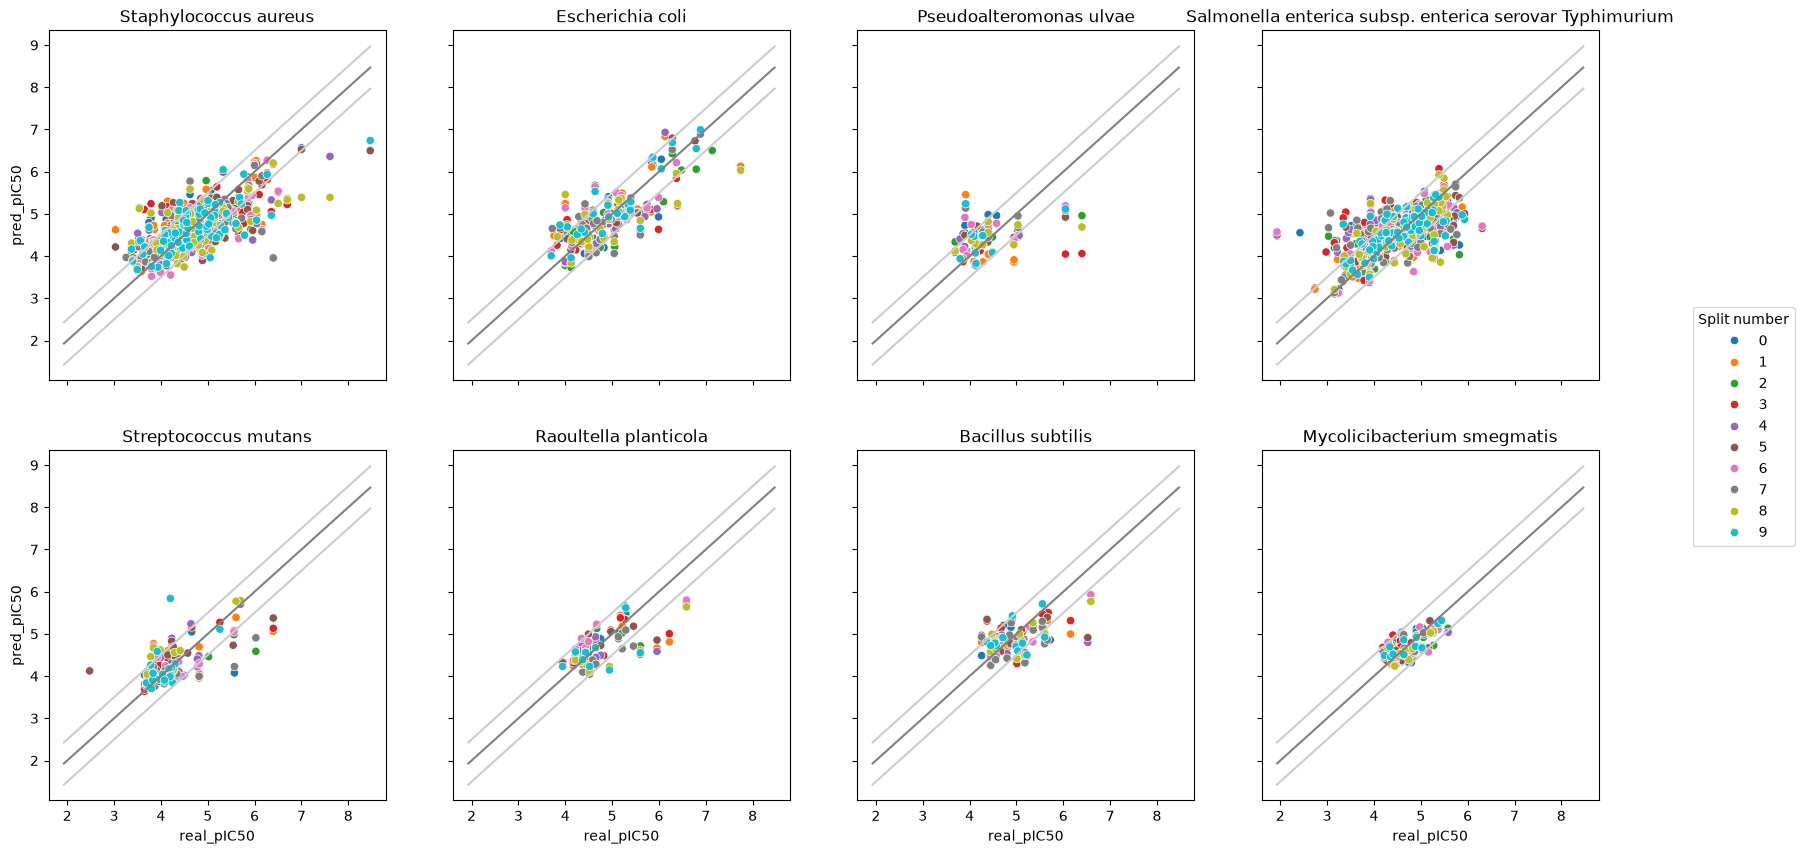

In [13]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [14]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.unique():
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Staphylococcus aureus,0.495,0.086,0.374,0.045,0.507,0.063
Escherichia coli,0.543,0.182,0.355,0.049,0.462,0.079
Pseudoalteromonas ulvae,-0.461,1.263,0.482,0.072,0.644,0.146
Salmonella enterica subsp. enterica serovar Typhimurium,0.385,0.083,0.378,0.036,0.537,0.052
Streptococcus mutans,0.249,0.442,0.344,0.070,0.481,0.086
Raoultella planticola,0.258,0.276,0.335,0.046,0.471,0.073
Bacillus subtilis,0.191,0.291,0.360,0.071,0.480,0.111
Mycolicibacterium smegmatis,0.361,0.272,0.217,0.037,0.256,0.041


In [15]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Staphylococcus aureus
r2_score 0.49533512572696925
MAE 0.37459042212817434
MSE 0.2603962589105963
RMSE 0.510290367252407
..............
Escherichia coli
r2_score 0.5823264862851708
MAE 0.35687486513158445
MSE 0.2215633917172654
RMSE 0.47070520680917205
..............
Pseudoalteromonas ulvae
r2_score -0.08785663282768086
MAE 0.4818868473612399
MSE 0.4351615140519416
RMSE 0.6596677300368281
..............
Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.3912106184111337
MAE 0.37886610936370646
MSE 0.29270146978735945
RMSE 0.541018918141833
..............
Streptococcus mutans
r2_score 0.3797284612345774
MAE 0.33984674081954697
MSE 0.23389644658855938
RMSE 0.48362841788769956
..............
Raoultella planticola
r2_score 0.3692099723188097
MAE 0.33460518452589916
MSE 0.22668556113861393
RMSE 0.4761150713205936
..............
Bacillus subtilis
r2_score 0.21953038504038302
MAE 0.3613614055759363
MSE 0.23978828852274717
RMSE 0.489681823761866
..............
Mycolicibacterium